# Занятие 7. Уравнение теплопроводности
**Как проверить численное решение?**

[Конспект](lesson_07_theory.md) · [План на 90 минут](PLAN.md) · [Домашняя работа](../README.md)

Основной маршрут — опыты 1–6. Дополнительные опыты после них можно выполнить самостоятельно.
Все параметры безразмерные. Для воспроизведения: установить зависимости из `requirements.txt`,
открыть ноутбук из папки `lesson7`, выбрать Python-ядро и выполнить **Restart Kernel and Run All**.
Реализации находятся в соседнем `heat_utils.py`; можно открыть его вместе с ноутбуком.

В опытах 1–4 и 6 неизвестные находятся во внутренних **узлах**, в опыте 5 — в **центрах ячеек**.
Не смешивайте эти два способа хранения при вычислении интегралов и граничных потоков.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from heat_utils import (nodal_operator, composite_operator, evolve, theta_step,
                        cooling_exact, stationary_composite, periodic_amplitude)

plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': .25,
                     'animation.embed_limit': 15})
METHODS = {'FTCS': 0., 'Неявный Эйлер': 1., 'Кранк—Николсон': .5}
COLORS = {'FTCS': '#2878b5', 'Неявный Эйлер': '#e58b25', 'Кранк—Николсон': '#32865b'}

def full_profile(op, u, left=0., right=0.):
    return np.r_[0., op.x, 1.], np.r_[left, u, right]

print('Импорты выполнены. Все расчёты детерминированы.')

Импорты выполнены. Все расчёты детерминированы.


## Опыт 1. Физическое сглаживание · 12–22 минуты
$$u_t=u_{xx},\quad u(0,t)=u(1,t)=0,\quad u_0=\sin\pi x+0.3\sin5\pi x.$$
Точный ответ: $u=e^{-\pi^2t}\sin\pi x+0.3e^{-25\pi^2t}\sin5\pi x$.
**Перед запуском:** какая гармоника исчезнет быстрее? Что останется на больших временах?

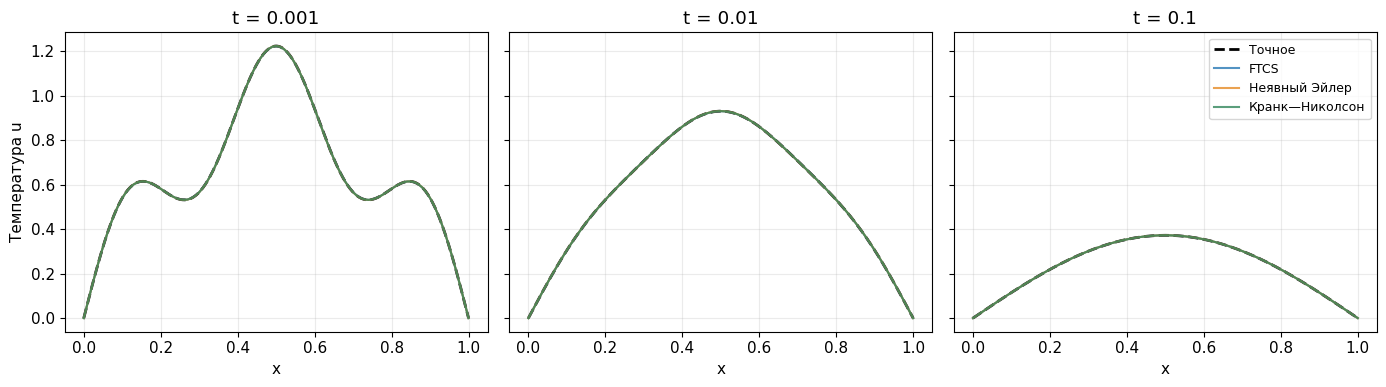

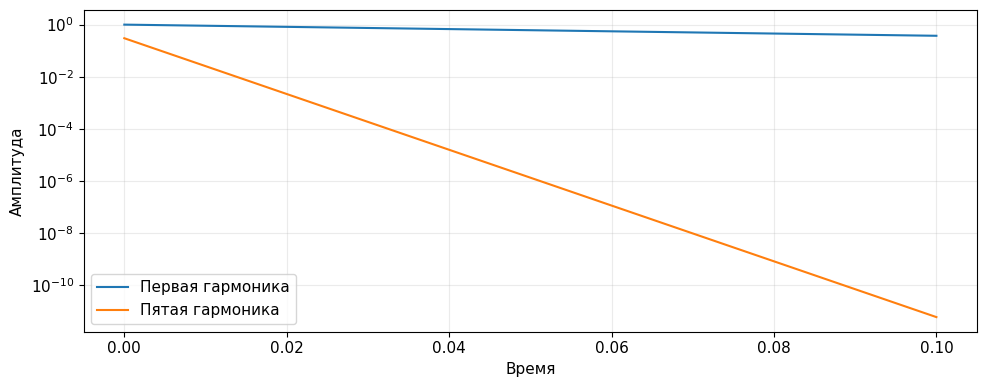

In [2]:
op = nodal_operator(100)
times = [0., .001, .01, .1]
results = {name: evolve(op, cooling_exact(op.x, 0), times, .4*op.h**2, th)
           for name, th in METHODS.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for j, ax in enumerate(axes, 1):
    xx = np.linspace(0, 1, 501)
    ax.plot(xx, cooling_exact(xx, times[j]), 'k--', lw=2, label='Точное')
    for name, res in results.items():
        x, y = full_profile(op, res['u'][j])
        ax.plot(x, y, color=COLORS[name], label=name, alpha=.8)
    ax.set(title=f't = {times[j]:g}', xlabel='x')
axes[0].set_ylabel('Температура u')
axes[-1].legend(fontsize=9)
fig.tight_layout()
plt.show()
t = np.linspace(0, .1, 300)
plt.semilogy(t, np.exp(-np.pi**2*t), label='Первая гармоника')
plt.semilogy(t, .3*np.exp(-25*np.pi**2*t), label='Пятая гармоника')
plt.xlabel('Время'); plt.ylabel('Амплитуда'); plt.legend(); plt.tight_layout(); plt.show()

In [3]:
# Анимация: одинаковые масштабы, точное и численное решения в одном кадре.
anim_t = np.linspace(0, .1, 51)
anim_res = evolve(op, cooling_exact(op.x, 0), anim_t, .4*op.h**2, .5)
fig, ax = plt.subplots()
x, y = full_profile(op, anim_res['u'][0])
line_num, = ax.plot(x, y, label='Кранк—Николсон')
line_exact, = ax.plot(x, cooling_exact(x, 0), 'k--', label='Точное')
ax.set(xlim=(0, 1), ylim=(-.05, 1.4), xlabel='x', ylabel='Температура u')
title = ax.set_title(''); ax.legend(); fig.tight_layout()
def animate(i):
    line_num.set_ydata(np.r_[0., anim_res['u'][i], 0.])
    line_exact.set_ydata(cooling_exact(x, anim_t[i]))
    title.set_text(f'Остывание: t = {anim_t[i]:.3f}')
    return line_num, line_exact, title
animation = FuncAnimation(fig, animate, frames=len(anim_t), interval=90, blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## Опыт 2. Параболическое ограничение шага · 22–37 минут
$$U_j^{n+1}=rU_{j-1}^n+(1-2r)U_j^n+rU_{j+1}^n,\qquad r=\tau/h^2.$$
При $r\le1/2$ это выпуклая комбинация. Для $r=0.6$ намеренно разрешаем неустойчивый расчёт.
Добавляем малую высокочастотную моду, чтобы увидеть рост до накопления ошибок округления.

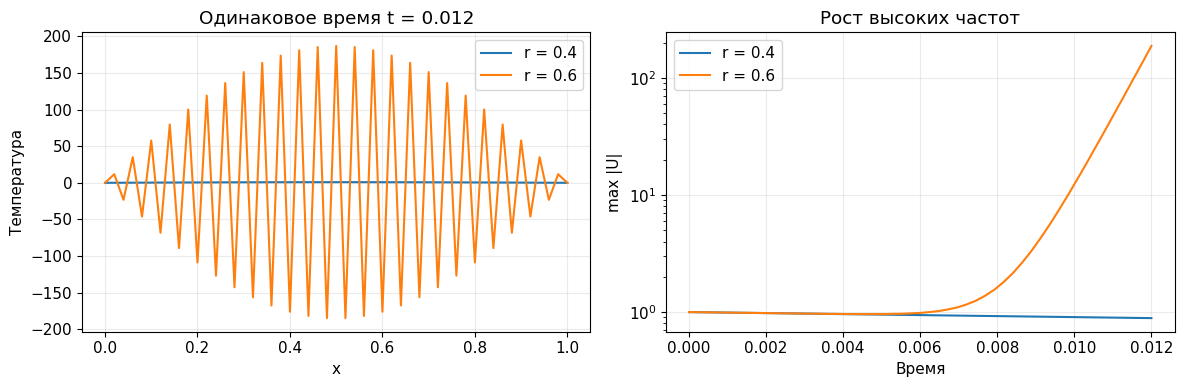

Максимумы в конце: {0.4: np.float64(0.8882608368003738), 0.6: np.float64(186.9438994379398)}


In [4]:
unstable_op = nodal_operator(50)
u0 = np.sin(np.pi*unstable_op.x) + 1e-5*np.sin(49*np.pi*unstable_op.x)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth = {}
for r in (.4, .6):
    dt = r*unstable_op.h**2
    ts = np.r_[np.arange(0, .012, dt), .012]
    res = evolve(unstable_op, u0, ts, dt, 0., allow_unstable=(r > .5))
    growth[r] = np.max(np.abs(res['u'][-1]))
    axes[0].plot(*full_profile(unstable_op, res['u'][-1]), label=f'r = {r}')
    axes[1].semilogy(ts, np.max(np.abs(res['u']), axis=1), label=f'r = {r}')
axes[0].set(xlabel='x', ylabel='Температура', title='Одинаковое время t = 0.012')
axes[1].set(xlabel='Время', ylabel='max |U|', title='Рост высоких частот')
for ax in axes: ax.legend()
fig.tight_layout(); plt.show()
assert growth[.6] > 10*growth[.4]
print('Максимумы в конце:', growth)

## Опыт 3. Безусловная устойчивость и осцилляции · 37–55 минут
Начальный профиль: нагретый участок $0.4\le x\le0.6$.
Сравниваем BE и CN при $r=10$; эталон — CN на той же сетке с $r=0.05$.
Это эталон для **временной**, а не полной ошибки. Не обрезаем отрицательные значения и зубцы.

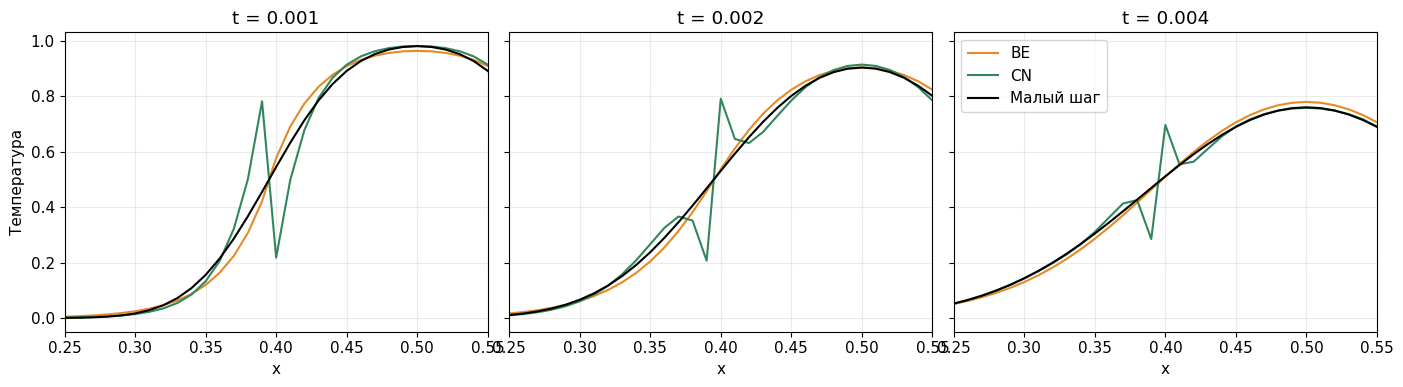

Слой   min(BE)   max(BE)   min(CN)   max(CN)
  0          0          1          0          1
  1   1.25e-06     0.9638  2.199e-08     0.9815
  2  8.332e-06      0.904  3.571e-07     0.9142
  3  3.004e-05     0.8394  2.741e-06     0.8242
  4  7.803e-05     0.7796  1.329e-05     0.7582


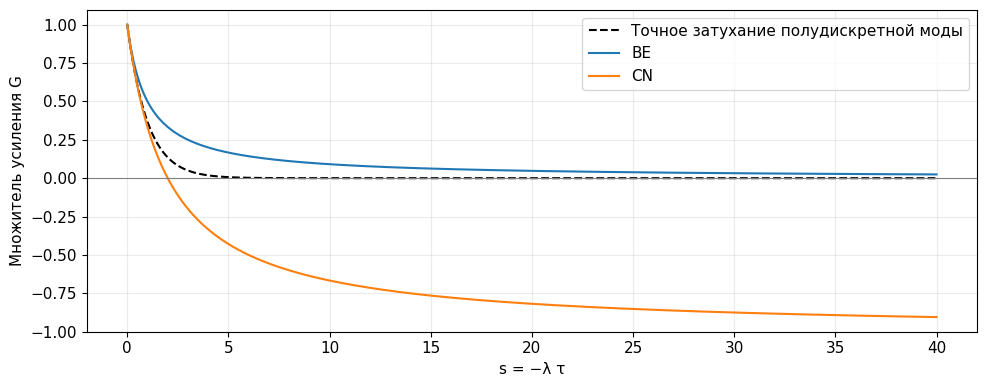

In [5]:
edge_op = nodal_operator(100)
box = ((edge_op.x >= .4) & (edge_op.x <= .6)).astype(float)
big_dt = 10*edge_op.h**2
early_t = np.arange(5)*big_dt
be = evolve(edge_op, box, early_t, big_dt, 1.)
cn = evolve(edge_op, box, early_t, big_dt, .5)
reference = evolve(edge_op, box, early_t, .05*edge_op.h**2, .5)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, i in zip(axes, (1, 2, 4)):
    for label, res, color in [('BE', be, '#e58b25'), ('CN', cn, '#32865b'),
                              ('Малый шаг', reference, 'black')]:
        ax.plot(edge_op.x, res['u'][i], label=label, color=color)
    ax.set(xlim=(.25, .55), xlabel='x', title=f't = {early_t[i]:.3f}')
axes[0].set_ylabel('Температура'); axes[-1].legend()
fig.tight_layout(); plt.show()
print('Слой   min(BE)   max(BE)   min(CN)   max(CN)')
for i in range(5):
    print(f'{i:3d} {be["u"][i].min():10.4g} {be["u"][i].max():10.4g}'
          f' {cn["u"][i].min():10.4g} {cn["u"][i].max():10.4g}')
s = np.linspace(0, 40, 400)
plt.plot(s, np.exp(-s), 'k--', label='Точное затухание полудискретной моды')
plt.plot(s, 1/(1+s), label='BE')
plt.plot(s, (1-s/2)/(1+s/2), label='CN')
plt.axhline(0, color='grey', lw=.8)
plt.xlabel('s = −λ τ'); plt.ylabel('Множитель усиления G'); plt.legend()
plt.tight_layout(); plt.show()

**Обсуждение.** CN сохраняет быстро меняющую знак сеточную составляющую, тогда как физическая
высокочастотная мода уже почти исчезла. Отрицательный $G$ не обязательно даёт отрицательную
температуру: в этом опыте важно увидеть зубцы около фронта, а не искать заранее заданный знак минимума.

## Опыт 4. Совместное сгущение сеток · 55–62 минуты
Сохраняем $r=0.4$, то есть $\tau=0.4h^2$, сравниваем при $t=0.01$.
Первый порядок по времени у Эйлера здесь совместим со вторым порядком по $h$.

FTCS 
  Ошибки: [2.89675118e-03 7.62492732e-04 1.91231652e-04 4.77646217e-05] 
  Порядки: [1.92564028 1.99540226 2.00130699]
Неявный Эйлер 
  Ошибки: [0.00706331 0.00185544 0.00046421 0.00011599] 
  Порядки: [1.92858079 1.99891054 2.00081691]
Кранк—Николсон 
  Ошибки: [2.01639632e-03 5.41170244e-04 1.36140091e-04 3.40891918e-05] 
  Порядки: [1.89762481 1.99099054 1.99770568]


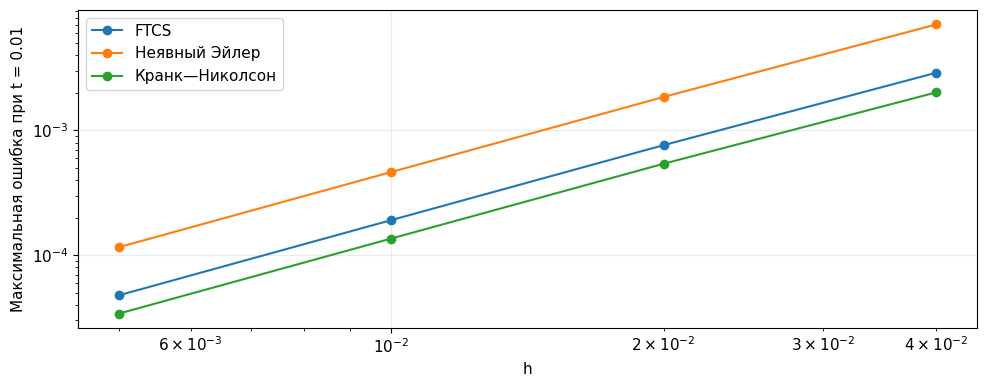

In [6]:
ns = [25, 50, 100, 200]
space_errors = {name: [] for name in METHODS}
for n in ns:
    grid = nodal_operator(n)
    for name, th in METHODS.items():
        res = evolve(grid, cooling_exact(grid.x, 0), [0, .01], .4*grid.h**2, th)
        space_errors[name].append(np.max(np.abs(res['u'][-1]-cooling_exact(grid.x, .01))))
for name, errors in space_errors.items():
    orders = np.log2(np.array(errors[:-1])/errors[1:])
    print(name, '\n  Ошибки:', np.array(errors), '\n  Порядки:', orders)
    assert 1.7 < orders[-1] < 2.3
    plt.loglog(1/np.array(ns), errors, 'o-', label=name)
plt.xlabel('h'); plt.ylabel('Максимальная ошибка при t = 0.01')
plt.legend(); plt.tight_layout(); plt.show()

## Опыт 5. Составной стержень и баланс · 62–76 минут
$u_t=(ku_x)_x$, $k_L=1$, $k_R=0.1$, $u(0)=1$, $u(1)=0$, $u_0=1-x$.
Теперь используем **ячейки**, а поток считаем по сопротивлению между их центрами.
При стационаре $q_*=2/11$, $u(0.5)=10/11$. Уравнение $u_t=ku_{xx}$ с центральной
разностью оставило бы исходный линейный профиль неизменным: его вторая производная равна нулю.

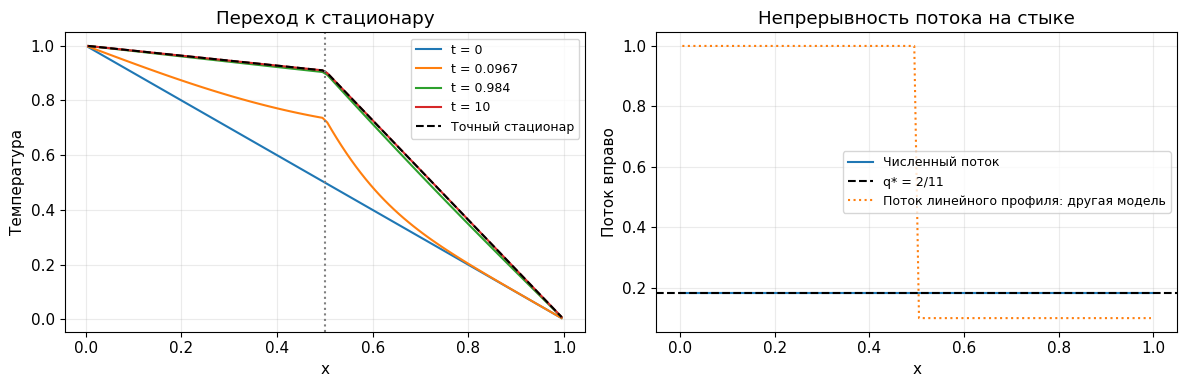

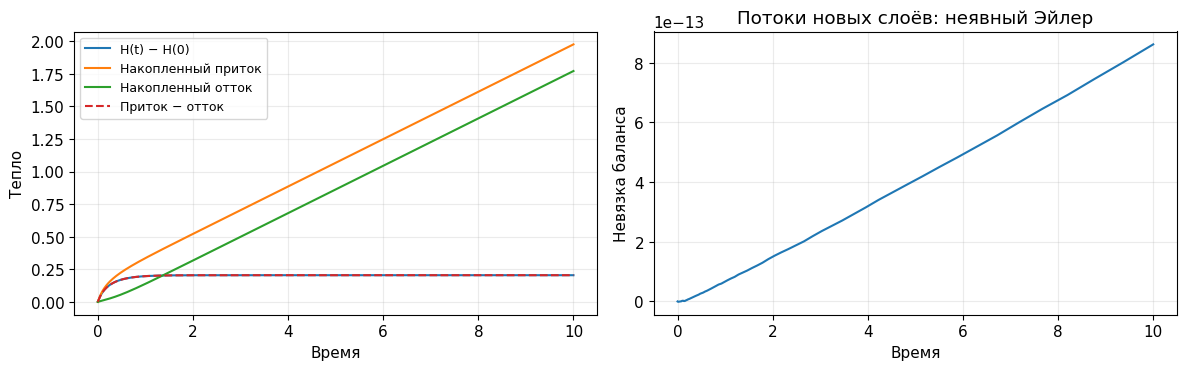

Ошибка стационарной температуры: 1.559863349598345e-14
Максимальная невязка баланса: 8.617551117140465e-13


In [7]:
material = composite_operator(100)
material_t = np.r_[0., np.geomspace(.001, 10., 140)]
mat = evolve(material, 1-material.x, material_t, .01, 1.)
steady, steady_flux = stationary_composite(material.x)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for target in (0., .1, 1., 10.):
    i = np.argmin(abs(material_t-target))
    axes[0].plot(material.x, mat['u'][i], label=f't = {material_t[i]:.3g}')
axes[0].plot(material.x, steady, 'k--', label='Точный стационар')
axes[0].axvline(.5, color='grey', ls=':')
axes[0].set(xlabel='x', ylabel='Температура', title='Переход к стационару')
axes[0].legend(fontsize=9)
faces = np.linspace(0, 1, 101)
axes[1].plot(faces, material.flux(mat['u'][-1], 10), label='Численный поток')
axes[1].axhline(steady_flux, color='black', ls='--', label='q* = 2/11')
axes[1].plot(material.x, np.where(material.x < .5, 1., .1), ':',
             label='Поток линейного профиля: другая модель')
axes[1].set(xlabel='x', ylabel='Поток вправо', title='Непрерывность потока на стыке')
axes[1].legend(fontsize=9); fig.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(material_t, mat['heat']-mat['heat'][0], label='H(t) − H(0)')
axes[0].plot(material_t, mat['incoming'], label='Накопленный приток')
axes[0].plot(material_t, mat['outgoing'], label='Накопленный отток')
axes[0].plot(material_t, mat['incoming']-mat['outgoing'], '--', label='Приток − отток')
axes[0].set(xlabel='Время', ylabel='Тепло'); axes[0].legend(fontsize=9)
axes[1].plot(material_t, mat['balance'])
axes[1].set(xlabel='Время', ylabel='Невязка баланса', title='Потоки новых слоёв: неявный Эйлер')
fig.tight_layout(); plt.show()
print('Ошибка стационарной температуры:', np.max(abs(mat['u'][-1]-steady)))
print('Максимальная невязка баланса:', np.max(abs(mat['balance'])))
assert np.max(abs(mat['balance'])) < 1e-9
assert np.max(abs(mat['u'][-1]-steady)) < 1e-6

**Важно:** кусочно-линейный стационар на согласованной сетке воспроизводится практически точно.
Не следует вычислять порядок сходимости по ошибкам около машинного нуля. График невязки баланса
показывает накопленные ошибки округления и решения линейных систем, а не ошибку температуры.

## Опыт 6. Периодический нагрев · 76–86 минут
$u(0,t)=\sin(8\pi t)$, $u(1,t)=0$, период $P=0.25$.
Считаем периоды, пока максимум различия соседних периодов **по всем узлам и фазам** не станет меньше $10^{-7}$.
Этот порог строже домашнего задания, чтобы переходный процесс не мешал сравнению фаз.

Периодов: 8; различие соседних: 7.382e-08; ошибка: 5.414e-05


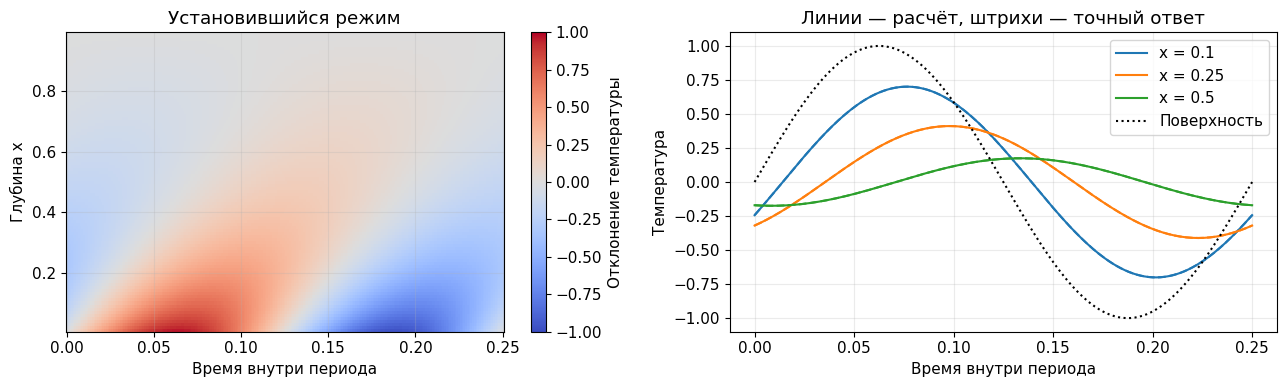

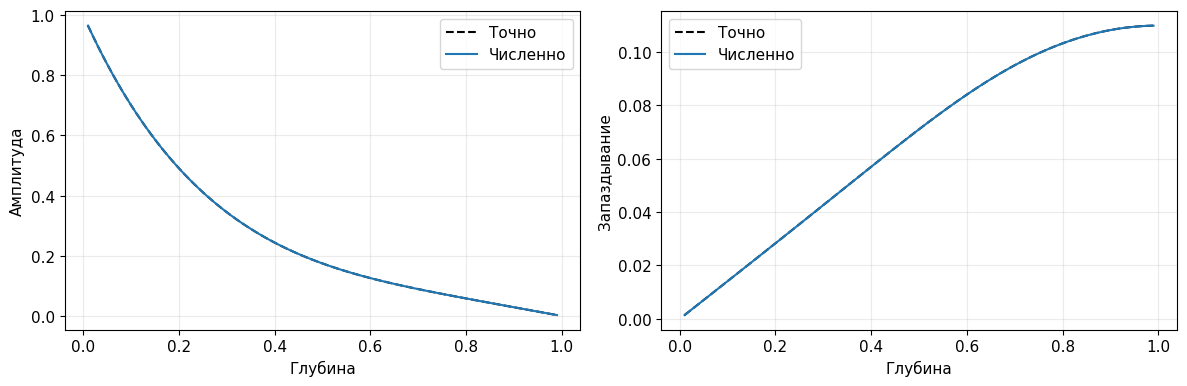

In [8]:
omega = 8*np.pi
period = 2*np.pi/omega
period_op = nodal_operator(100, left=lambda t: np.sin(omega*t))
phase_times = np.linspace(0, period, 251)
u_start = np.zeros_like(period_op.x)
previous = None
for cycle in range(1, 31):
    # Граница строго периодична: каждый цикл можно считать в локальном времени.
    cyc = evolve(period_op, u_start, phase_times, period/1000, .5)
    cycle_difference = (np.inf if previous is None else
                        np.max(abs(cyc['u']-previous)))
    if cycle_difference < 1e-7:
        break
    previous = cyc['u'].copy()
    u_start = cyc['u'][-1].copy()
else:
    raise RuntimeError('Периодический режим не достигнут за 30 периодов')
amplitude = periodic_amplitude(period_op.x, omega)
exact_period = np.imag(np.exp(1j*omega*phase_times[:, None])*amplitude[None, :])
period_error = np.max(abs(cyc['u']-exact_period))
print(f'Периодов: {cycle}; различие соседних: {cycle_difference:.3e}; ошибка: {period_error:.3e}')
assert period_error < 2e-3
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].pcolormesh(phase_times, period_op.x, cyc['u'].T,
                        shading='auto', cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], label='Отклонение температуры')
axes[0].set(xlabel='Время внутри периода', ylabel='Глубина x', title='Установившийся режим')
for depth in (.1, .25, .5):
    j = np.argmin(abs(period_op.x-depth))
    line, = axes[1].plot(phase_times, cyc['u'][:, j], label=f'x = {depth}')
    axes[1].plot(phase_times, exact_period[:, j], '--', color=line.get_color())
axes[1].plot(phase_times, np.sin(omega*phase_times), 'k:', label='Поверхность')
axes[1].set(xlabel='Время внутри периода', ylabel='Температура', title='Линии — расчёт, штрихи — точный ответ')
axes[1].legend(); fig.tight_layout(); plt.show()
# u(t) = a sin(ωt) + b cos(ωt): комплексная амплитуда A = a + ib.
design = np.c_[np.sin(omega*phase_times[:-1]), np.cos(omega*phase_times[:-1])]
coeff = np.linalg.lstsq(design, cyc['u'][:-1], rcond=None)[0]
numeric_amp = coeff[0] + 1j*coeff[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(period_op.x, abs(amplitude), 'k--', label='Точно')
axes[0].plot(period_op.x, abs(numeric_amp), label='Численно')
axes[0].set(xlabel='Глубина', ylabel='Амплитуда'); axes[0].legend()
axes[1].plot(period_op.x, -np.unwrap(np.angle(amplitude))/omega, 'k--', label='Точно')
axes[1].plot(period_op.x, -np.unwrap(np.angle(numeric_amp))/omega, label='Численно')
axes[1].set(xlabel='Глубина', ylabel='Запаздывание'); axes[1].legend()
fig.tight_layout(); plt.show()

## Дополнение A. Порядок по времени отдельно от пространства
На фиксированной узловой сетке синус — собственный вектор $L_h$ с
$\lambda_h=-4h^{-2}\sin^2(\pi h/2)$. Сравниваем с $e^{\lambda_ht}\sin\pi x$.
Так пространственная ошибка не скрывает временной порядок. Показываем два неявных метода,
чтобы ограничение явного шага не сокращало диапазон эксперимента.

Неявный Эйлер порядки: [0.97510848 0.98758567 0.99380964 0.99691033 0.99845672]
Кранк—Николсон порядки: [2.00286507 2.00071459 2.00017854 2.00004462 2.00001115]


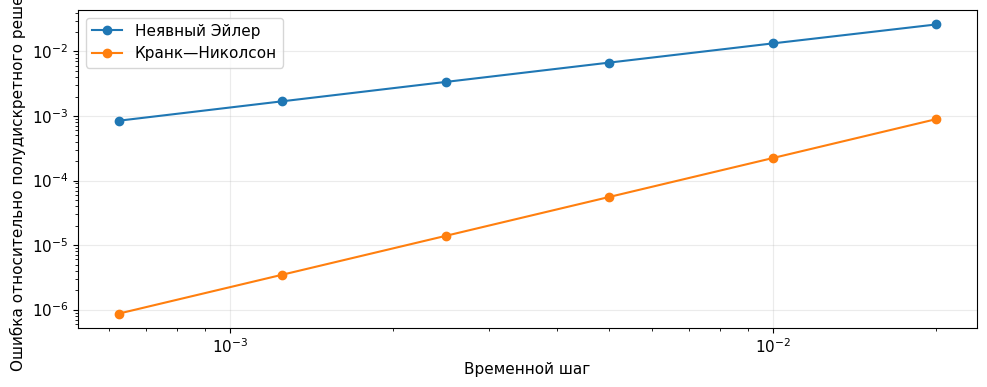

In [9]:
time_op = nodal_operator(80)
dt_values = .02/2**np.arange(6)
lam_h = -4/time_op.h**2*np.sin(np.pi*time_op.h/2)**2
time_orders = {}
for name, th in [('Неявный Эйлер', 1.), ('Кранк—Николсон', .5)]:
    errors = []
    for dt in dt_values:
        res = evolve(time_op, np.sin(np.pi*time_op.x), [0., .2], dt, th)
        exact = np.exp(lam_h*.2)*np.sin(np.pi*time_op.x)
        errors.append(np.max(abs(res['u'][-1]-exact)))
    orders = np.log2(np.array(errors[:-1])/errors[1:])
    time_orders[name] = orders[-1]
    print(name, 'порядки:', orders)
    plt.loglog(dt_values, errors, 'o-', label=name)
assert .9 < time_orders['Неявный Эйлер'] < 1.1
assert 1.9 < time_orders['Кранк—Николсон'] < 2.1
plt.xlabel('Временной шаг'); plt.ylabel('Ошибка относительно полудискретного решения')
plt.legend(); plt.tight_layout(); plt.show()

## Дополнение B. Сглаживающий старт CN
Заменим первый большой шаг двумя полушагами неявного Эйлера, затем продолжим CN.
Сравним при тех же временах. Это демонстрация приёма, а не полный подбор оптимального старта.

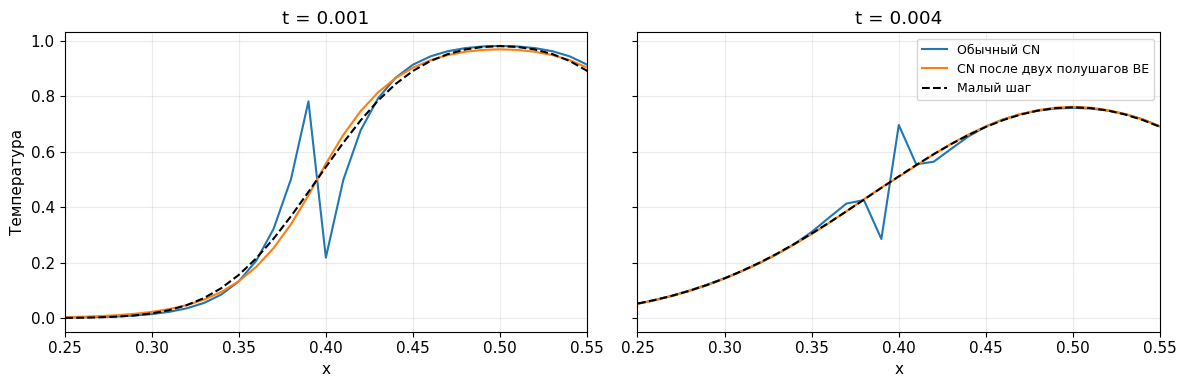

In [10]:
u_half = theta_step(edge_op, box, 0., big_dt/2, 1.)
u_first = theta_step(edge_op, u_half, big_dt/2, big_dt/2, 1.)
smoothed = [box.copy(), u_first.copy()]
for i in range(1, 4):
    u_first = theta_step(edge_op, u_first, i*big_dt, big_dt, .5)
    smoothed.append(u_first.copy())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, i in zip(axes, (1, 4)):
    ax.plot(edge_op.x, cn['u'][i], label='Обычный CN')
    ax.plot(edge_op.x, smoothed[i], label='CN после двух полушагов BE')
    ax.plot(edge_op.x, reference['u'][i], 'k--', label='Малый шаг')
    ax.set(xlim=(.25, .55), xlabel='x', title=f't = {early_t[i]:.3f}')
axes[0].set_ylabel('Температура'); axes[1].legend(fontsize=9)
fig.tight_layout(); plt.show()

## Дополнение C. Контакт и частота нагрева
Два независимых продолжения домашних сюжетов. При контактном сопротивлении поток непрерывен,
а температура скачет. Рост частоты уменьшает глубину проникновения тепловых колебаний.

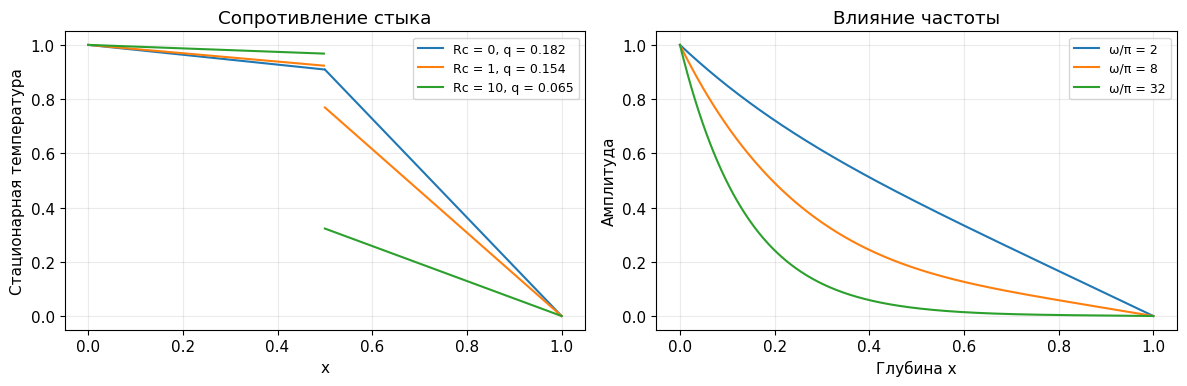

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.linspace(0, 1, 501)
for resistance in (0., 1., 10.):
    yy, q = stationary_composite(xx, contact=resistance)
    # Раздельные линии не маскируют физический скачок на стыке.
    left_mask, right_mask = xx < .5, xx >= .5
    line, = axes[0].plot(xx[left_mask], yy[left_mask], label=f'Rc = {resistance:g}, q = {q:.3f}')
    axes[0].plot(xx[right_mask], yy[right_mask], color=line.get_color())
for w in (2*np.pi, 8*np.pi, 32*np.pi):
    axes[1].plot(xx, abs(periodic_amplitude(xx, w)), label=f'ω/π = {w/np.pi:g}')
axes[0].set(xlabel='x', ylabel='Стационарная температура', title='Сопротивление стыка')
axes[1].set(xlabel='Глубина x', ylabel='Амплитуда', title='Влияние частоты')
for ax in axes: ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

## Проверка расчётных функций
Проверяем не только формулы в реализации, но и независимые свойства: стационарный точный
профиль, постоянный поток, баланс на нестационарном решении и временную обработку границ.

In [12]:
# Для нескольких сеток и сопротивлений стационар не должен изменяться.
for n in (20, 40, 80):
    for resistance in (0., 1.):
        check_op = composite_operator(n, contact=resistance)
        equilibrium, q = stationary_composite(check_op.x, contact=resistance)
        check = evolve(check_op, equilibrium, [0., .1], .01, .5)
        assert np.max(abs(check['u'][-1]-equilibrium)) < 1e-11
        assert np.max(abs(check_op.flux(equilibrium, 0)-q)) < 1e-11
        transient = evolve(check_op, 1-check_op.x, [0., .1], .01, .5)
        assert np.max(abs(transient['balance'])) < 1e-11
# Ненулевые постоянные границы: линейный профиль — точный стационар.
boundary_op = nodal_operator(40, left=lambda t: 2., right=lambda t: -1.)
linear = 2-3*boundary_op.x
for th in (0., .5, 1.):
    check = evolve(boundary_op, linear, [0., .01], .4*boundary_op.h**2, th)
    assert np.max(abs(check['u'][-1]-linear)) < 1e-11
print('Все проверки пройдены: сходимость, устойчивость, стационары, потоки и баланс.')

Все проверки пройдены: сходимость, устойчивость, стационары, потоки и баланс.


## Домашняя работа
Выбрать один вариант в README: **7.1** — остывание и схемы; **7.2** — составной стержень;
**7.3** — периодический нагрев. Перед сдачей объяснить, какой эталон использован,
что происходит с шагом по времени при сгущении сетки и какие физические свойства проверены.
Готовые демонстрации помогают освоить методы; домашняя работа требует собственных сравнений
и выводов для параметров, указанных в условии.